# Project: CH05 – Employee Attrition Insight
## Round 1: Data Understanding, Preparation and Exploratory Data Analysis (EDA)
**Data Science Sprint Assessment Deliverable**

> **Note**: This dataset contains 500 synthetic employee records designed specifically for assessment practice. All findings and analyses are performed strictly on the provided five CSV files without any external data generation or fabrication.

---

### Notebook Structure & Objectives:
1. **Setup & Configuration**: Ingest required scientific libraries and configure visualization styling.
2. **Data Understanding**: Safely load all five CSV files with error handling, inspect dimensions, data types, initial records, summary statistics, missing values, and duplicates.
3. **Data Preprocessing & Preparation**:
   - Deduplicate attendance records
   - Standardize inconsistent job role names (trimming whitespace and normalizing capitalization)
   - Handle missing engagement survey scores using median imputation
   - Detect and treat extreme overtime values using the IQR method (capping / Winsorization)
   - Handle missing promotion history using median imputation
   - Verify primary key consistency across all tables and merge on `employee_id`
   - Validate post-cleaning data integrity (zero nulls, zero duplicates, exactly 500 unique employees)
4. **Exploratory Data Analysis (EDA)**:
   - Chart 1: Attrition rate by department
   - Chart 2: Attrition rate by job role
   - Chart 3: Tenure comparison between employees who left and stayed
   - Chart 4: Average monthly overtime comparison by exit status
   - Chart 5: Engagement score comparison by exit status
   - Chart 6: Promotion history versus exit status
5. **Key Findings & Insights**: Programmatically compute and report key findings, clearly distinguishing empirical observations from possible explanations.
6. **Deliverables Export**: Save `cleaned_employee_attrition.csv`, `round1_eda_report.txt`, and all high-resolution charts to the `outputs/` folder.

## 1. Setup & Library Imports
Import necessary scientific computing and visualization packages: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, and utility modules.

In [15]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Ensure output directory exists
os.makedirs('outputs', exist_ok=True)
print("Libraries imported and visualization styling configured successfully.")

Libraries imported and visualization styling configured successfully.


## 2. Data Understanding
Load all five CSV files with robust error handling to guard against missing files and verify expected schema attributes.
Display dataset dimensions, data types, first 5 records, summary statistics, missing values, and duplicate records.

In [16]:
# Expected CSV files and primary key
data_dir = 'dataset' if os.path.exists('dataset') else '.'
file_names = {
    'employees': os.path.join(data_dir, 'employees.csv'),
    'attendance': os.path.join(data_dir, 'attendance.csv'),
    'compensation': os.path.join(data_dir, 'compensation.csv'),
    'engagement': os.path.join(data_dir, 'engagement.csv'),
    'movement': os.path.join(data_dir, 'movement.csv')
}

raw_data = {}

# Load each file safely with error handling
for name, filename in file_names.items():
    try:
        if not os.path.exists(filename):
            raise FileNotFoundError(f"Required file '{filename}' was not found in the workspace.")
        df = pd.read_csv(filename)
        if 'employee_id' not in df.columns:
            raise KeyError(f"Expected primary key 'employee_id' not found in '{filename}'.")
        raw_data[name] = df
        print(f"Loaded '{filename}' successfully: {df.shape[0]} records, {df.shape[1]} attributes.")
    except Exception as e:
        print(f"Error loading {filename}: {e}", file=sys.stderr)
        raise

print("\nAll five CSV files loaded successfully.")


Loaded 'dataset\employees.csv' successfully: 500 records, 6 attributes.
Loaded 'dataset\attendance.csv' successfully: 508 records, 4 attributes.
Loaded 'dataset\compensation.csv' successfully: 500 records, 5 attributes.
Loaded 'dataset\engagement.csv' successfully: 500 records, 3 attributes.
Loaded 'dataset\movement.csv' successfully: 500 records, 4 attributes.

All five CSV files loaded successfully.


### 2.1 Schema, Missing Values, and Duplicates Inspection
Inspect each table's attribute types, null values, and duplicate rows.

In [17]:
for name, df in raw_data.items():
    print("=" * 65)
    print(f"TABLE: {name}.csv")
    print(f"Dimensions: {df.shape[0]} records, {df.shape[1]} attributes")
    print(f"Duplicate Rows Count: {df.duplicated().sum()}")
    print("\nAttributes & Data Types:")
    for col, dtype in df.dtypes.items():
        print(f"  - {col:<24}: {dtype}")
    print("\nMissing Values:")
    for col, null_count in df.isnull().sum().items():
        print(f"  - {col:<24}: {null_count}")
    print("\nFirst 5 Records:")
    display(df.head())
    print()

TABLE: employees.csv
Dimensions: 500 records, 6 attributes
Duplicate Rows Count: 0

Attributes & Data Types:
  - employee_id             : object
  - department              : object
  - role                    : object
  - tenure_years            : float64
  - grade                   : object
  - age                     : int64

Missing Values:
  - employee_id             : 0
  - department              : 0
  - role                    : 0
  - tenure_years            : 0
  - grade                   : 0
  - age                     : 0

First 5 Records:


,employee_id,department,role,tenure_years,grade,age
0,E0001,Operations,Operations Manager,4.1,G2,27
1,E0002,Sales,Sales Manager,0.5,G3,55
2,E0003,Operations,Team Lead,2.1,G1,51
3,E0004,Operations,Operations Manager,5.2,G4,46
4,E0005,IT,Software Engineer,1.8,G2,40



TABLE: attendance.csv
Dimensions: 508 records, 4 attributes
Duplicate Rows Count: 8

Attributes & Data Types:
  - employee_id             : object
  - absence_days            : int64
  - overtime_hours_monthly  : float64
  - leave_days              : int64

Missing Values:
  - employee_id             : 0
  - absence_days            : 0
  - overtime_hours_monthly  : 0
  - leave_days              : 0

First 5 Records:


,employee_id,absence_days,overtime_hours_monthly,leave_days
0,E0001,7,14.8,9
1,E0002,5,10.3,9
2,E0003,3,46.4,11
3,E0004,5,42.2,11
4,E0005,4,41.5,13



TABLE: compensation.csv
Dimensions: 500 records, 5 attributes
Duplicate Rows Count: 0

Attributes & Data Types:
  - employee_id             : object
  - salary_band             : object
  - monthly_salary          : int64
  - increment_band          : object
  - benefits                : object

Missing Values:
  - employee_id             : 0
  - salary_band             : 0
  - monthly_salary          : 0
  - increment_band          : 0
  - benefits                : 0

First 5 Records:


,employee_id,salary_band,monthly_salary,increment_band,benefits
0,E0001,Band 1,33500,3-6%,Basic
1,E0002,Band 3,52200,10%+,Basic
2,E0003,Band 1,18000,6-10%,Basic
3,E0004,Band 4,73100,0-3%,Basic
4,E0005,Band 2,41800,3-6%,Basic



TABLE: engagement.csv
Dimensions: 500 records, 3 attributes
Duplicate Rows Count: 0

Attributes & Data Types:
  - employee_id             : object
  - survey_score            : float64
  - participation_pct       : int64

Missing Values:
  - employee_id             : 0
  - survey_score            : 20
  - participation_pct       : 0

First 5 Records:


,employee_id,survey_score,participation_pct
0,E0001,1.8,85
1,E0002,4.3,77
2,E0003,3.0,73
3,E0004,3.7,35
4,E0005,3.8,77



TABLE: movement.csv
Dimensions: 500 records, 4 attributes
Duplicate Rows Count: 0

Attributes & Data Types:
  - employee_id             : object
  - promotion_count         : float64
  - transfer_count          : int64
  - exit_status             : object

Missing Values:
  - employee_id             : 0
  - promotion_count         : 15
  - transfer_count          : 0
  - exit_status             : 0

First 5 Records:


,employee_id,promotion_count,transfer_count,exit_status
0,E0001,1.0,0,Yes
1,E0002,2.0,0,No
2,E0003,1.0,0,Yes
3,E0004,2.0,1,Yes
4,E0005,1.0,0,No


### 2.2 Descriptive Statistics
Compute summary statistics for numeric and categorical attributes across all raw tables.

In [18]:
for name, df in raw_data.items():
    print(f"=== Descriptive Statistics for {name}.csv ===")
    display(df.describe(include='all'))

=== Descriptive Statistics for employees.csv ===


,employee_id,department,role,tenure_years,grade,age
count,500,500,500,500.000000,500,500.000000
unique,500,6,29,NaN,5,NaN
top,E0001,IT,IT Support,NaN,G2,NaN
freq,1,132,41,NaN,151,NaN
mean,NaN,NaN,NaN,4.857600,NaN,40.508000
std,NaN,NaN,NaN,2.996933,NaN,11.894069
min,NaN,NaN,NaN,0.200000,NaN,21.000000
25%,NaN,NaN,NaN,2.700000,NaN,30.000000
50%,NaN,NaN,NaN,4.300000,NaN,41.000000
75%,NaN,NaN,NaN,6.200000,NaN,51.000000


=== Descriptive Statistics for attendance.csv ===


,employee_id,absence_days,overtime_hours_monthly,leave_days
count,508,508.000000,508.000000,508.000000
unique,500,NaN,NaN,NaN
top,E0153,NaN,NaN,NaN
freq,2,NaN,NaN,NaN
mean,NaN,3.891732,18.381496,8.194882
std,NaN,2.013292,18.793434,2.922303
min,NaN,0.000000,0.600000,1.000000
25%,NaN,2.000000,8.900000,6.000000
50%,NaN,4.000000,14.900000,8.000000
75%,NaN,5.000000,23.100000,10.000000


=== Descriptive Statistics for compensation.csv ===


,employee_id,salary_band,monthly_salary,increment_band,benefits
count,500,500,500.000000,500,500
unique,500,5,NaN,4,3
top,E0001,Band 2,NaN,3-6%,Standard
freq,1,169,NaN,220,256
mean,NaN,NaN,51914.400000,NaN,NaN
std,NaN,NaN,21943.045987,NaN,NaN
min,NaN,NaN,18000.000000,NaN,NaN
25%,NaN,NaN,35775.000000,NaN,NaN
50%,NaN,NaN,46050.000000,NaN,NaN
75%,NaN,NaN,64400.000000,NaN,NaN


=== Descriptive Statistics for engagement.csv ===


,employee_id,survey_score,participation_pct
count,500,480.000000,500.000000
unique,500,NaN,NaN
top,E0001,NaN,NaN
freq,1,NaN,NaN
mean,NaN,3.224792,64.996000
std,NaN,0.777227,18.842028
min,NaN,1.000000,7.000000
25%,NaN,2.700000,52.000000
50%,NaN,3.200000,65.000000
75%,NaN,3.800000,78.000000


=== Descriptive Statistics for movement.csv ===


,employee_id,promotion_count,transfer_count,exit_status
count,500,485.000000,500.000000,500
unique,500,NaN,NaN,2
top,E0001,NaN,NaN,No
freq,1,NaN,NaN,367
mean,NaN,0.717526,0.390000,NaN
std,NaN,0.862800,0.598847,NaN
min,NaN,0.000000,0.000000,NaN
25%,NaN,0.000000,0.000000,NaN
50%,NaN,1.000000,0.000000,NaN
75%,NaN,1.000000,1.000000,NaN


## 3. Data Preprocessing & Cleaning
In this phase, we address data quality issues systematically:
1. **Attendance Deduplication**: Remove duplicate attendance rows (8 exact duplicates).
2. **Role Name Standardization**: Trim whitespace and normalize capitalization to resolve casing inconsistencies (12 records).
3. **Engagement Score Imputation**: Impute missing survey scores using the median value (20 records).
4. **Overtime Outlier Treatment**: Detect and cap extreme overtime hours using the IQR method (16 records capped at upper fence 44.4 hours).
5. **Promotion History Imputation**: Impute missing promotion counts using the median value (15 records).
6. **Key Consistency & Merge**: Verify employee ID consistency across tables and merge on `employee_id`.
7. **Post-Cleaning Verification**: Confirm zero missing values, zero duplicates, and exactly 500 unique employees.

In [19]:
# -------------------------------------------------------------------------
# Step 1: Remove duplicate attendance records
# -------------------------------------------------------------------------
attendance_raw = raw_data['attendance']
attendance_dup_count = attendance_raw.duplicated().sum()
attendance_clean = attendance_raw.drop_duplicates().copy()

print(f"Step 1 - Attendance Duplicates:")
print(f"  Rows before deduplication : {attendance_raw.shape[0]}")
print(f"  Duplicate records removed  : {attendance_dup_count}")
print(f"  Rows after deduplication   : {attendance_clean.shape[0]}")

# -------------------------------------------------------------------------
# Step 2: Standardize inconsistent role names
# -------------------------------------------------------------------------
employees_clean = raw_data['employees'].copy()

# Identify records with non-standard capitalization or whitespace
raw_roles = employees_clean['role']
inconsistent_mask = (raw_roles != raw_roles.str.strip()) | raw_roles.str.isupper()
roles_affected = inconsistent_mask.sum()

# Standardize: strip whitespace, title-case, and restore canonical acronyms
employees_clean['role'] = employees_clean['role'].str.strip().str.title()
acronym_corrections = {
    'It Support': 'IT Support',
    'Hr Manager': 'HR Manager',
    'Hr Executive': 'HR Executive',
    'Devops Engineer': 'DevOps Engineer'
}
employees_clean['role'] = employees_clean['role'].replace(acronym_corrections)

print(f"\nStep 2 - Role Name Standardization:")
print(f"  Unique roles before cleaning : {raw_roles.nunique()}")
print(f"  Records affected             : {roles_affected}")
print(f"  Unique roles after cleaning  : {employees_clean['role'].nunique()}")
print(f"  Standardized Roles List      : {sorted(employees_clean['role'].unique())}")

# -------------------------------------------------------------------------
# Step 3: Handle missing survey scores via median imputation
# -------------------------------------------------------------------------
engagement_clean = raw_data['engagement'].copy()
missing_survey_count = engagement_clean['survey_score'].isnull().sum()
survey_score_median = engagement_clean['survey_score'].median()

engagement_clean['survey_score'] = engagement_clean['survey_score'].fillna(survey_score_median)

print(f"\nStep 3 - Missing Survey Score Imputation:")
print(f"  Missing survey_score values : {missing_survey_count}")
print(f"  Median survey_score used    : {survey_score_median:.2f}")
print(f"  Remaining nulls             : {engagement_clean['survey_score'].isnull().sum()}")

# -------------------------------------------------------------------------
# Step 4: Detect and treat extreme overtime values using the IQR method
# -------------------------------------------------------------------------
q1 = attendance_clean['overtime_hours_monthly'].quantile(0.25)
q3 = attendance_clean['overtime_hours_monthly'].quantile(0.75)
iqr = q3 - q1
lower_fence = max(0.0, q1 - 1.5 * iqr)
upper_fence = q3 + 1.5 * iqr

overtime_outliers_mask = (attendance_clean['overtime_hours_monthly'] < lower_fence) | (attendance_clean['overtime_hours_monthly'] > upper_fence)
overtime_outliers_count = overtime_outliers_mask.sum()

# Treat using Winsorization / Capping to upper fence to preserve all valid records
attendance_clean['overtime_hours_monthly'] = attendance_clean['overtime_hours_monthly'].clip(lower=lower_fence, upper=upper_fence)

print(f"\nStep 4 - Extreme Overtime IQR Detection & Treatment:")
print(f"  Q1: {q1:.2f} hrs | Q3: {q3:.2f} hrs | IQR: {iqr:.2f} hrs")
print(f"  Lower Fence: {lower_fence:.2f} hrs | Upper Fence: {upper_fence:.2f} hrs")
print(f"  Outliers detected and capped: {overtime_outliers_count}")

# -------------------------------------------------------------------------
# Step 5: Handle missing promotion history via median imputation
# -------------------------------------------------------------------------
movement_clean = raw_data['movement'].copy()
missing_promo_count = movement_clean['promotion_count'].isnull().sum()
promo_median = movement_clean['promotion_count'].median()

movement_clean['promotion_count'] = movement_clean['promotion_count'].fillna(promo_median)

print(f"\nStep 5 - Missing Promotion History Imputation:")
print(f"  Missing promotion_count values : {missing_promo_count}")
print(f"  Median promotion_count used    : {promo_median:.1f}")
print(f"  Remaining nulls                : {movement_clean['promotion_count'].isnull().sum()}")

# -------------------------------------------------------------------------
# Step 6: Verify key consistency across tables and merge
# -------------------------------------------------------------------------
base_ids = set(employees_clean['employee_id'])
for table_name, df_sub in [('attendance', attendance_clean), ('compensation', raw_data['compensation']),
                           ('engagement', engagement_clean), ('movement', movement_clean)]:
    diff = base_ids.symmetric_difference(set(df_sub['employee_id']))
    if diff:
        raise ValueError(f"Key mismatch between employees and {table_name}: {diff}")

print(f"\nStep 6 - Primary Key Verification:")
print("  All 5 datasets have 100% consistent employee_id sets (500 unique IDs).")

merged_df = employees_clean.merge(attendance_clean, on='employee_id') \
                           .merge(raw_data['compensation'], on='employee_id') \
                           .merge(engagement_clean, on='employee_id') \
                           .merge(movement_clean, on='employee_id')

# -------------------------------------------------------------------------
# Step 7: Post-cleaning validation
# -------------------------------------------------------------------------
print(f"\nStep 7 - Merged Dataset Validation:")
print(f"  Merged Shape                 : {merged_df.shape} (500 records, 18 attributes)")
print(f"  Unique Employee IDs          : {merged_df['employee_id'].nunique()}")
print(f"  Total Missing Values in DF   : {merged_df.isnull().sum().sum()}")
print(f"  Total Duplicate Rows in DF   : {merged_df.duplicated().sum()}")
assert len(merged_df) == 500 and merged_df['employee_id'].nunique() == 500
assert merged_df.isnull().sum().sum() == 0 and merged_df.duplicated().sum() == 0
print("  Data Integrity Check Passed: Exactly 500 unique employees, 0 missing values, 0 duplicates.")

Step 1 - Attendance Duplicates:
  Rows before deduplication : 508
  Duplicate records removed  : 8
  Rows after deduplication   : 500

Step 2 - Role Name Standardization:
  Unique roles before cleaning : 29
  Records affected             : 12
  Unique roles after cleaning  : 19
  Standardized Roles List      : ['Account Manager', 'Accountant', 'Content Specialist', 'Data Analyst', 'DevOps Engineer', 'Finance Manager', 'Financial Analyst', 'HR Executive', 'HR Manager', 'IT Support', 'Marketing Executive', 'Marketing Manager', 'Operations Associate', 'Operations Manager', 'Recruiter', 'Sales Executive', 'Sales Manager', 'Software Engineer', 'Team Lead']

Step 3 - Missing Survey Score Imputation:
  Missing survey_score values : 20
  Median survey_score used    : 3.20
  Remaining nulls             : 0

Step 4 - Extreme Overtime IQR Detection & Treatment:
  Q1: 8.90 hrs | Q3: 23.10 hrs | IQR: 14.20 hrs
  Lower Fence: 0.00 hrs | Upper Fence: 44.40 hrs
  Outliers detected and capped: 16

Step

### 3.1 Dataset Dimensions Before and After Cleaning
Verify the exact dimensions before and after preprocessing across all individual datasets and the final merged dataset.

In [20]:
print("=" * 65)
print("DATASET DIMENSIONS SUMMARY")
print("=" * 65)
print(f"{'Dataset Name':<20} | {'Before Cleaning':<18} | {'After Cleaning':<18}")
print("-" * 65)
print(f"{'employees.csv':<20} | {str(raw_data['employees'].shape):<18} | {str(employees_clean.shape):<18}")
print(f"{'attendance.csv':<20} | {str(raw_data['attendance'].shape):<18} | {str(attendance_clean.shape):<18}")
print(f"{'compensation.csv':<20} | {str(raw_data['compensation'].shape):<18} | {str(raw_data['compensation'].shape):<18}")
print(f"{'engagement.csv':<20} | {str(raw_data['engagement'].shape):<18} | {str(engagement_clean.shape):<18}")
print(f"{'movement.csv':<20} | {str(raw_data['movement'].shape):<18} | {str(movement_clean.shape):<18}")
print("-" * 65)
print(f"{'FINAL MERGED DATASET':<20} | {'--':<18} | {str(merged_df.shape):<18}")
print("=" * 65)

DATASET DIMENSIONS SUMMARY
Dataset Name         | Before Cleaning    | After Cleaning    
-----------------------------------------------------------------
employees.csv        | (500, 6)           | (500, 6)          
attendance.csv       | (508, 4)           | (500, 4)          
compensation.csv     | (500, 5)           | (500, 5)          
engagement.csv       | (500, 3)           | (500, 3)          
movement.csv         | (500, 4)           | (500, 4)          
-----------------------------------------------------------------
FINAL MERGED DATASET | --                 | (500, 18)         


## 4. Exploratory Data Analysis (EDA)
In this section, we analyze workforce attrition patterns and explore factors related to employee exits across 6 focused visualizations:
1. Attrition rate by department
2. Attrition rate by job role
3. Tenure comparison between employees who left and stayed
4. Average monthly overtime comparison by exit status
5. Engagement score comparison by exit status
6. Promotion history versus exit status

### 4.1 Chart 1: Attrition Rate by Department
Analyze the proportion of employees leaving within each functional department compared against the company baseline.

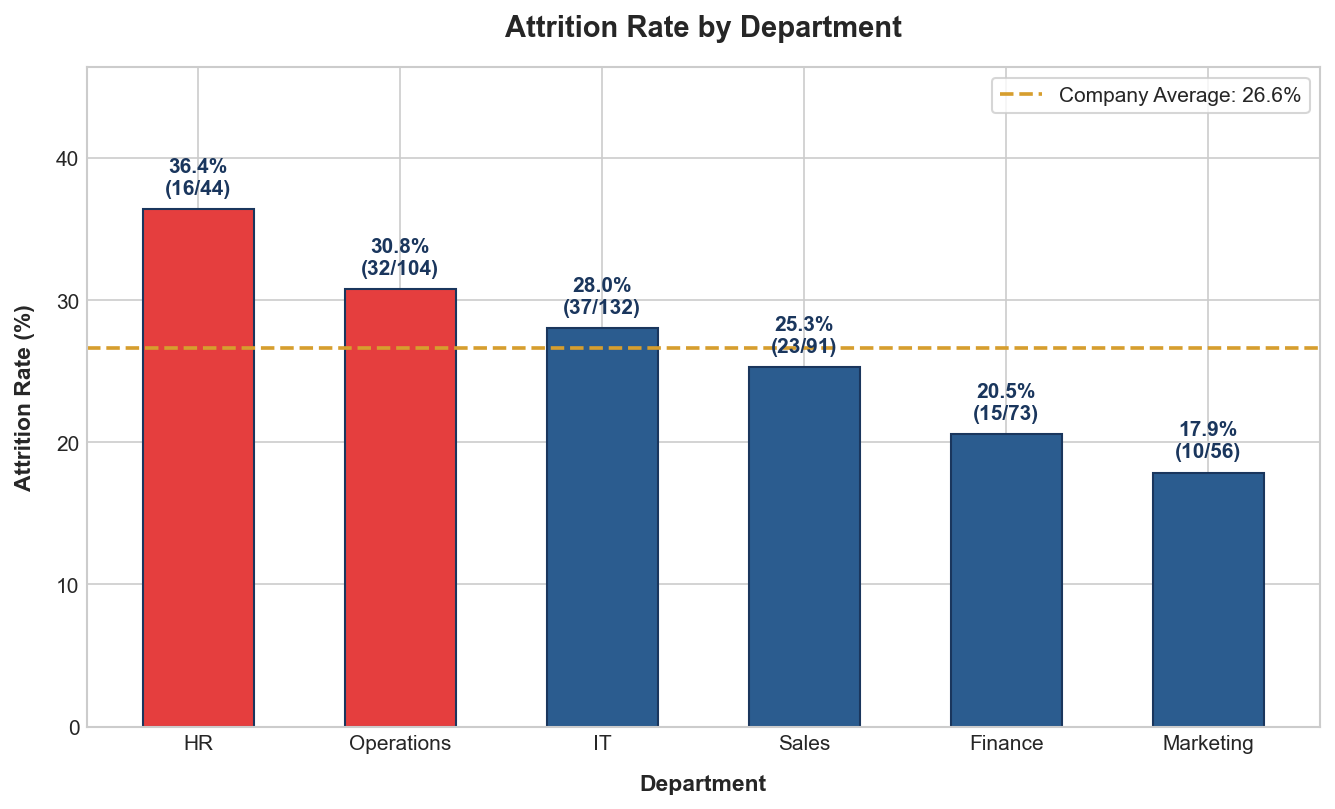

,total,left,attrition_rate
department,,,
HR,44,16,36.363636
Operations,104,32,30.769231
IT,132,37,28.030303
Sales,91,23,25.274725
Finance,73,15,20.547945
Marketing,56,10,17.857143


In [21]:
dept_summary = merged_df.groupby('department').agg(
    total=('employee_id', 'count'),
    left=('exit_status', lambda x: (x == 'Yes').sum())
)
dept_summary['attrition_rate'] = (dept_summary['left'] / dept_summary['total']) * 100
dept_summary = dept_summary.sort_values('attrition_rate', ascending=False)

overall_attrition = (merged_df['exit_status'] == 'Yes').mean() * 100

fig, ax = plt.subplots(figsize=(9, 5.5))
palette = ['#e53e3e' if r >= 30 else '#2b5c8f' for r in dept_summary['attrition_rate']]
bars = ax.bar(dept_summary.index, dept_summary['attrition_rate'], color=palette, edgecolor='#1a365d', width=0.55)

ax.axhline(overall_attrition, color='#d69e2e', linestyle='--', linewidth=1.75, label=f"Company Average: {overall_attrition:.1f}%")

for bar, (dept, row) in zip(bars, dept_summary.iterrows()):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.8,
            f"{height:.1f}%\n({int(row['left'])}/{int(row['total'])})",
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1a365d')

ax.set_title("Attrition Rate by Department", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Department", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Attrition Rate (%)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylim(0, dept_summary['attrition_rate'].max() + 10)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig('outputs/01_attrition_rate_by_department.png', dpi=300)
plt.show()

display(dept_summary)

### 4.2 Chart 2: Attrition Rate by Job Role
Examine attrition rate variations across individual job roles to detect occupational vulnerability.

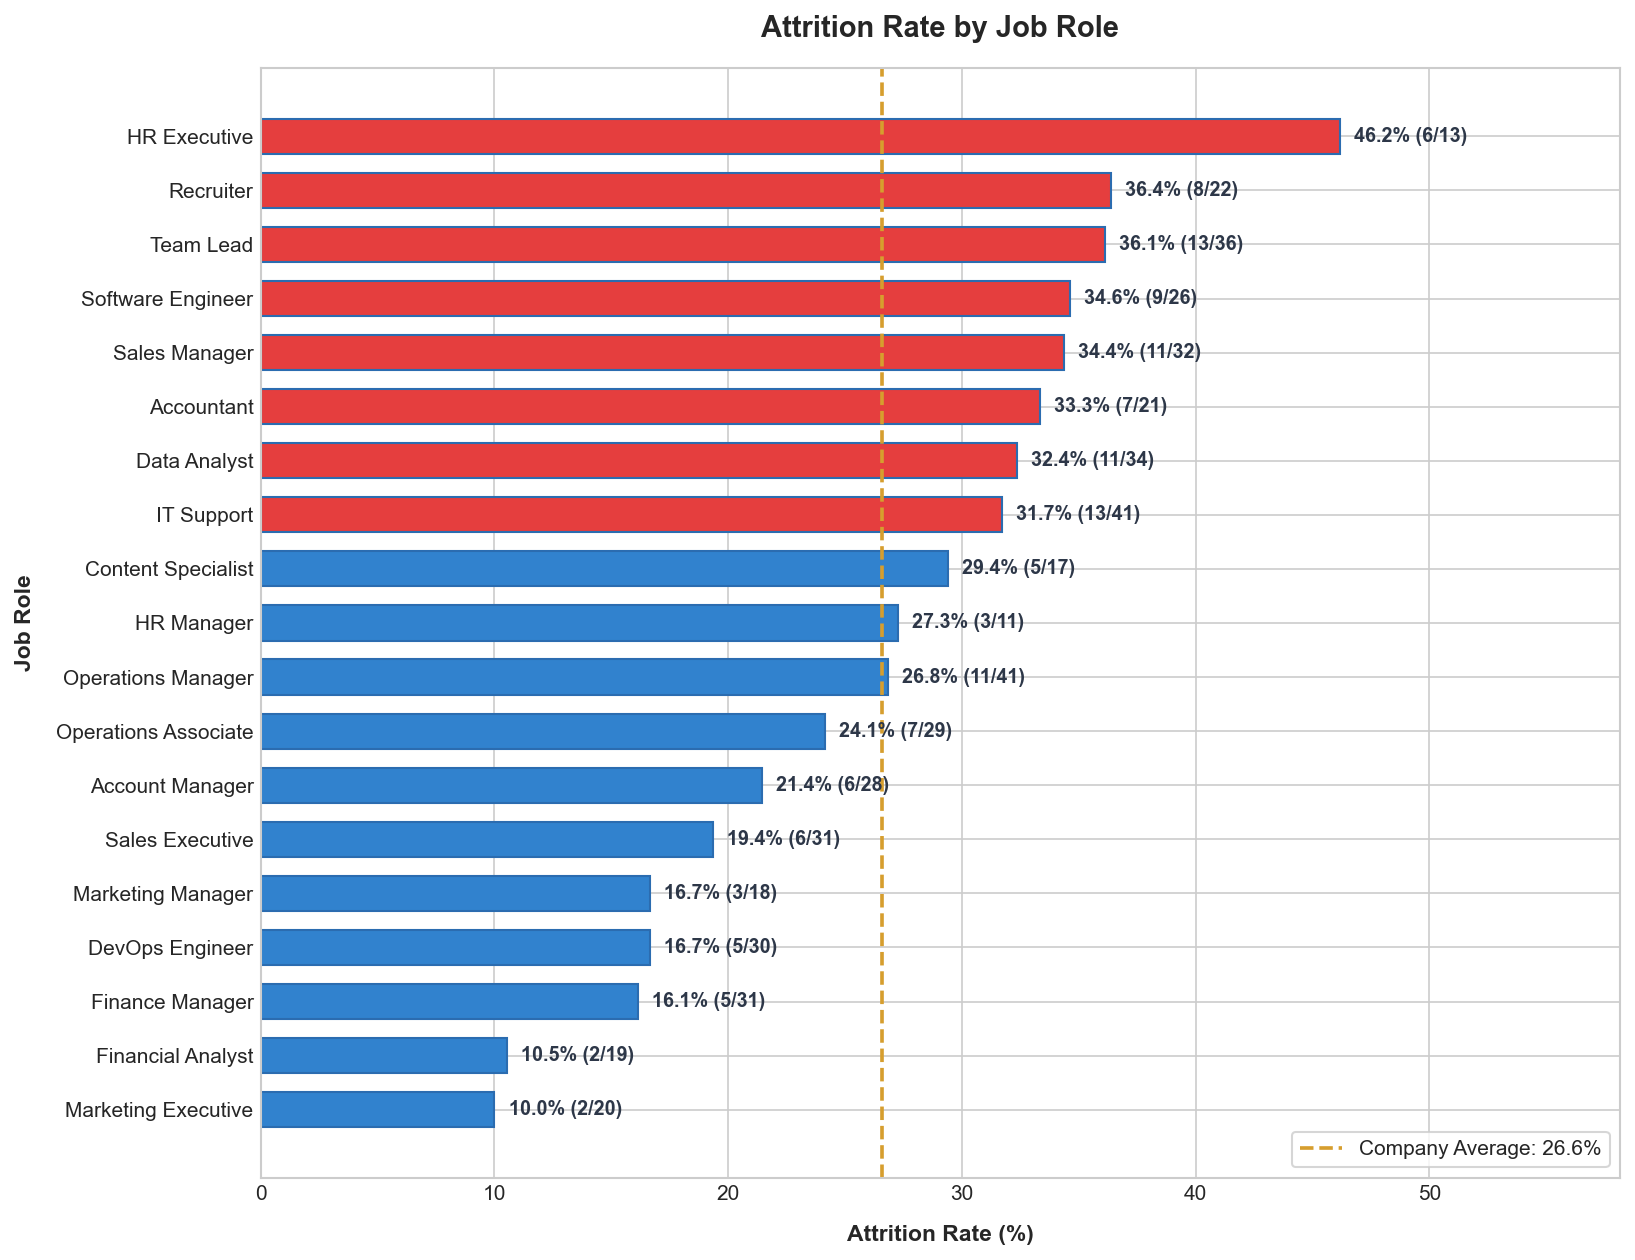

In [22]:
role_summary = merged_df.groupby('role').agg(
    total=('employee_id', 'count'),
    left=('exit_status', lambda x: (x == 'Yes').sum())
)
role_summary['attrition_rate'] = (role_summary['left'] / role_summary['total']) * 100
role_summary = role_summary.sort_values('attrition_rate', ascending=True)

fig, ax = plt.subplots(figsize=(11, 8.5))
y_positions = np.arange(len(role_summary))
colors = ['#e53e3e' if r >= 30 else '#3182ce' for r in role_summary['attrition_rate']]
bars = ax.barh(y_positions, role_summary['attrition_rate'], color=colors, edgecolor='#2b6cb0', height=0.65)

ax.axvline(overall_attrition, color='#d69e2e', linestyle='--', linewidth=1.75, label=f"Company Average: {overall_attrition:.1f}%")

for bar, (role, row) in zip(bars, role_summary.iterrows()):
    width = bar.get_width()
    ax.text(width + 0.6, bar.get_y() + bar.get_height()/2,
            f"{width:.1f}% ({int(row['left'])}/{int(row['total'])})",
            ha='left', va='center', fontsize=9.5, fontweight='bold', color='#2d3748')

ax.set_yticks(y_positions)
ax.set_yticklabels(role_summary.index, fontsize=10)
ax.set_title("Attrition Rate by Job Role", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Attrition Rate (%)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Job Role", fontsize=11, fontweight='bold', labelpad=10)
ax.set_xlim(0, role_summary['attrition_rate'].max() + 12)
ax.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.savefig('outputs/02_attrition_rate_by_job_role.png', dpi=300)
plt.show()

### 4.3 Chart 3: Tenure Comparison Between Employees Who Left and Stayed
Analyze whether organizational tenure differs between exiting employees and continuing employees.

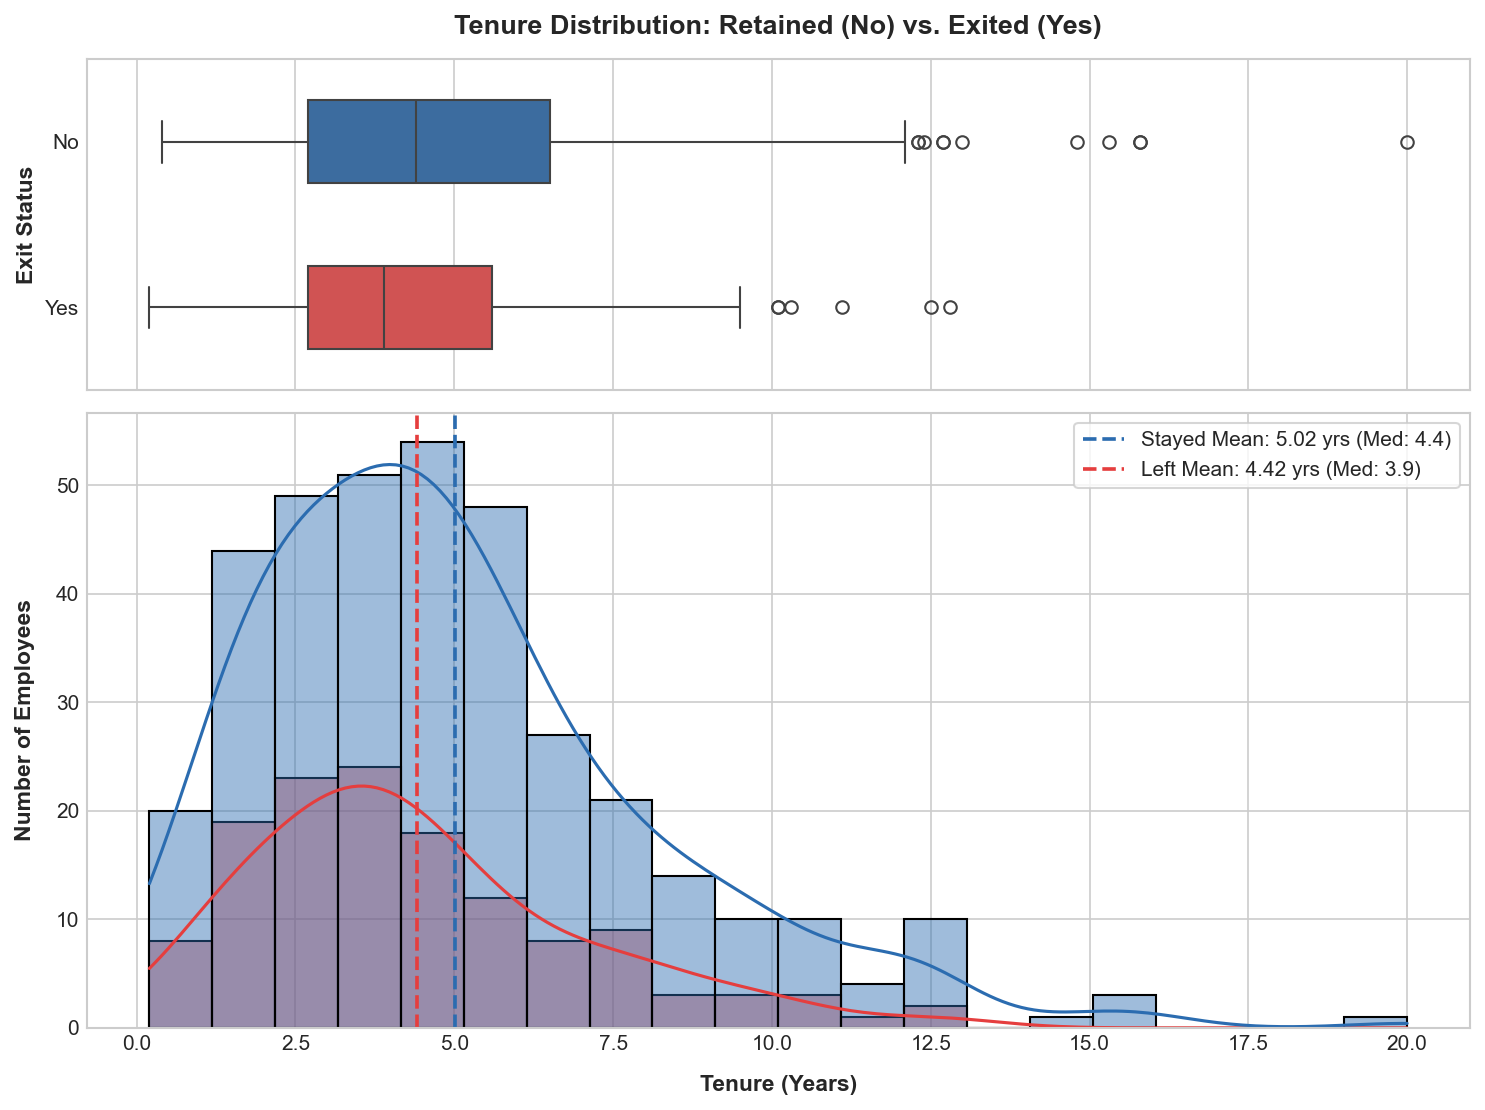

             count      mean       std  min  25%  50%  75%   max
exit_status                                                     
No           367.0  5.017166  3.120863  0.4  2.7  4.4  6.5  20.0
Yes          133.0  4.417293  2.584819  0.2  2.7  3.9  5.6  12.8


In [23]:
palette_status = {'No': '#2b6cb0', 'Yes': '#e53e3e'}

fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 7.5), gridspec_kw={'height_ratios': [0.35, 0.65]}, sharex=True)

sns.boxplot(data=merged_df, x='tenure_years', y='exit_status', order=['No', 'Yes'], ax=ax_box, palette=palette_status, hue='exit_status', legend=False, width=0.5)
ax_box.set_title("Tenure Distribution: Retained (No) vs. Exited (Yes)", fontsize=13, fontweight='bold', pad=12)
ax_box.set_ylabel("Exit Status", fontsize=11, fontweight='bold')
ax_box.set_xlabel("")

sns.histplot(data=merged_df, x='tenure_years', hue='exit_status', hue_order=['No', 'Yes'], kde=True, ax=ax_hist, palette=palette_status, bins=20, alpha=0.45)
ax_hist.set_xlabel("Tenure (Years)", fontsize=11, fontweight='bold', labelpad=10)
ax_hist.set_ylabel("Number of Employees", fontsize=11, fontweight='bold', labelpad=10)

mean_stayed = merged_df[merged_df['exit_status'] == 'No']['tenure_years'].mean()
mean_left = merged_df[merged_df['exit_status'] == 'Yes']['tenure_years'].mean()
median_stayed = merged_df[merged_df['exit_status'] == 'No']['tenure_years'].median()
median_left = merged_df[merged_df['exit_status'] == 'Yes']['tenure_years'].median()

ax_hist.axvline(mean_stayed, color='#2b6cb0', linestyle='--', linewidth=1.75, label=f"Stayed Mean: {mean_stayed:.2f} yrs (Med: {median_stayed:.1f})")
ax_hist.axvline(mean_left, color='#e53e3e', linestyle='--', linewidth=1.75, label=f"Left Mean: {mean_left:.2f} yrs (Med: {median_left:.1f})")
ax_hist.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.savefig('outputs/03_tenure_comparison.png', dpi=300)
plt.show()

print(merged_df.groupby('exit_status')['tenure_years'].describe())

### 4.4 Chart 4: Average Overtime Comparison by Exit Status
Evaluate monthly overtime workload disparities between employees who stayed versus those who exited.

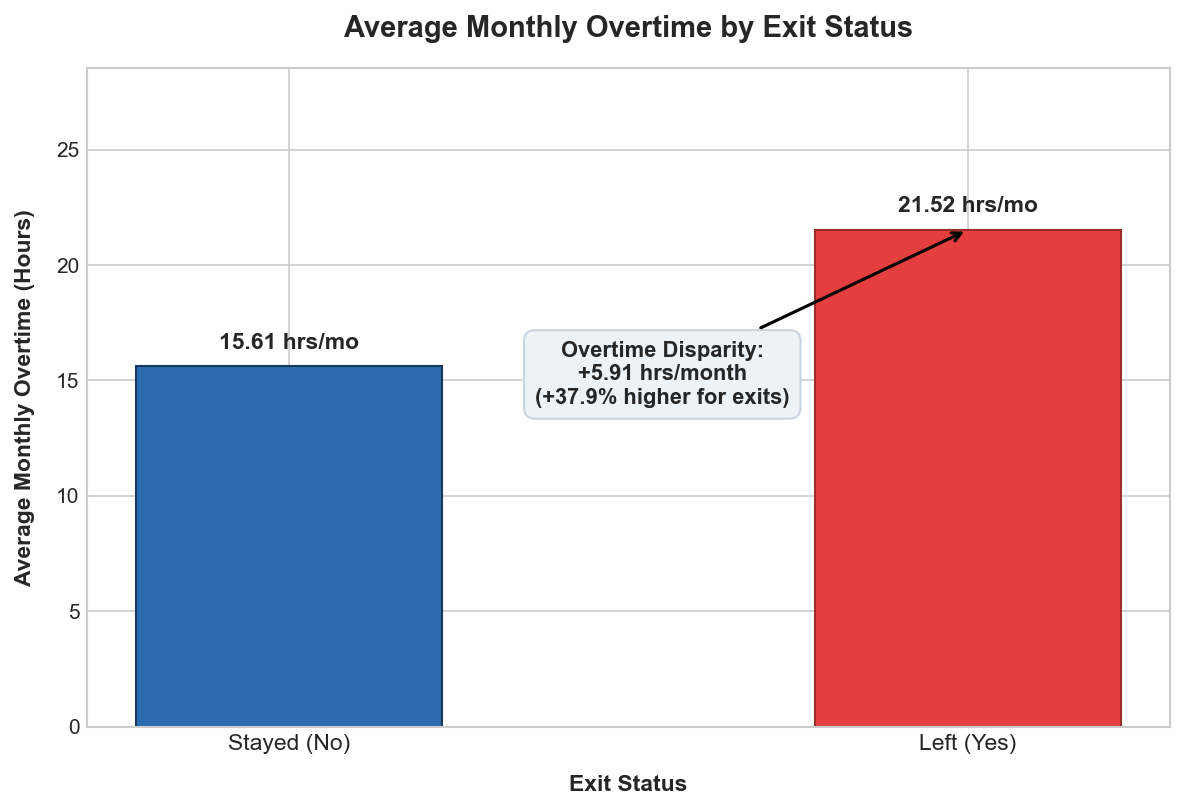

,exit_status,mean,median,std,count
0,No,15.611172,13.6,9.816330,367
1,Yes,21.524060,19.7,12.168664,133


In [24]:
ot_summary = merged_df.groupby('exit_status')['overtime_hours_monthly'].agg(['mean', 'median', 'std', 'count']).reindex(['No', 'Yes']).reset_index()

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(ot_summary['exit_status'], ot_summary['mean'], color=['#2b6cb0', '#e53e3e'], edgecolor=['#1a365d', '#9b2c2c'], width=0.45)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.6, f"{yval:.2f} hrs/mo", ha='center', va='bottom', fontsize=11, fontweight='bold')

ot_left_val = ot_summary.loc[ot_summary['exit_status'] == 'Yes', 'mean'].values[0]
ot_stayed_val = ot_summary.loc[ot_summary['exit_status'] == 'No', 'mean'].values[0]
ot_diff_val = ot_left_val - ot_stayed_val
pct_higher = (ot_diff_val / ot_stayed_val) * 100

ax.annotate(f"Overtime Disparity:\n+{ot_diff_val:.2f} hrs/month\n(+{pct_higher:.1f}% higher for exits)",
            xy=(1, ot_left_val), xytext=(0.55, ot_left_val * 0.65),
            arrowprops=dict(facecolor='#2d3748', arrowstyle='->', lw=1.5),
            ha='center', fontsize=10.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#edf2f7', edgecolor='#cbd5e0'))

ax.set_title("Average Monthly Overtime by Exit Status", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Exit Status", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Average Monthly Overtime (Hours)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (No)", "Left (Yes)"], fontsize=11)
ax.set_ylim(0, ot_summary['mean'].max() + 7)
plt.tight_layout()
plt.savefig('outputs/04_overtime_comparison.png', dpi=300)
plt.show()

display(ot_summary)

### 4.5 Chart 5: Engagement Score Comparison by Exit Status
Analyze employee engagement survey scores across retention groups.

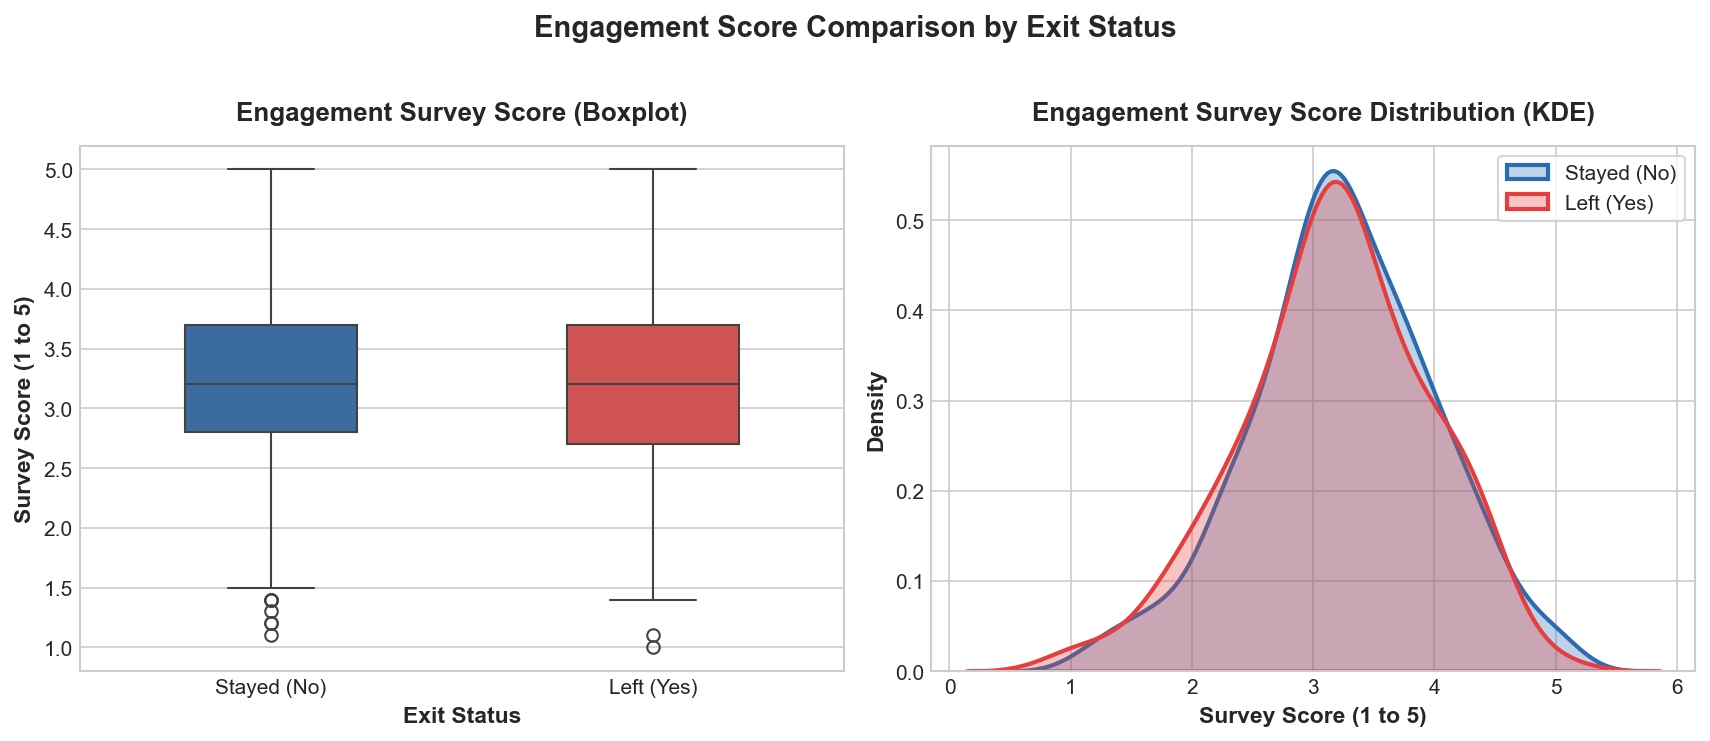

             count      mean       std  min  25%  50%  75%  max
exit_status                                                    
No           367.0  3.240327  0.760434  1.1  2.8  3.2  3.7  5.0
Yes          133.0  3.178195  0.765480  1.0  2.7  3.2  3.7  5.0


In [25]:
fig, (ax_box, ax_kde) = plt.subplots(1, 2, figsize=(11.5, 4.8))

sns.boxplot(data=merged_df, x='exit_status', y='survey_score', order=['No', 'Yes'], ax=ax_box, palette=palette_status, hue='exit_status', legend=False, width=0.45)
ax_box.set_title("Engagement Survey Score (Boxplot)", fontsize=12.5, fontweight='bold', pad=12)
ax_box.set_xlabel("Exit Status", fontsize=11, fontweight='bold')
ax_box.set_ylabel("Survey Score (1 to 5)", fontsize=11, fontweight='bold')
ax_box.set_xticks([0, 1])
ax_box.set_xticklabels(["Stayed (No)", "Left (Yes)"])

sns.kdeplot(data=merged_df[merged_df['exit_status'] == 'No']['survey_score'], ax=ax_kde, label='Stayed (No)', color='#2b6cb0', fill=True, alpha=0.3, linewidth=2)
sns.kdeplot(data=merged_df[merged_df['exit_status'] == 'Yes']['survey_score'], ax=ax_kde, label='Left (Yes)', color='#e53e3e', fill=True, alpha=0.3, linewidth=2)
ax_kde.set_title("Engagement Survey Score Distribution (KDE)", fontsize=12.5, fontweight='bold', pad=12)
ax_kde.set_xlabel("Survey Score (1 to 5)", fontsize=11, fontweight='bold')
ax_kde.set_ylabel("Density", fontsize=11, fontweight='bold')
ax_kde.legend(frameon=True, facecolor='white', loc='upper right')

plt.suptitle("Engagement Score Comparison by Exit Status", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('outputs/05_engagement_score_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(merged_df.groupby('exit_status')['survey_score'].describe())

### 4.6 Chart 6: Promotion History versus Exit Status
Investigate the relationship between career progression (promotions received) and workforce attrition.

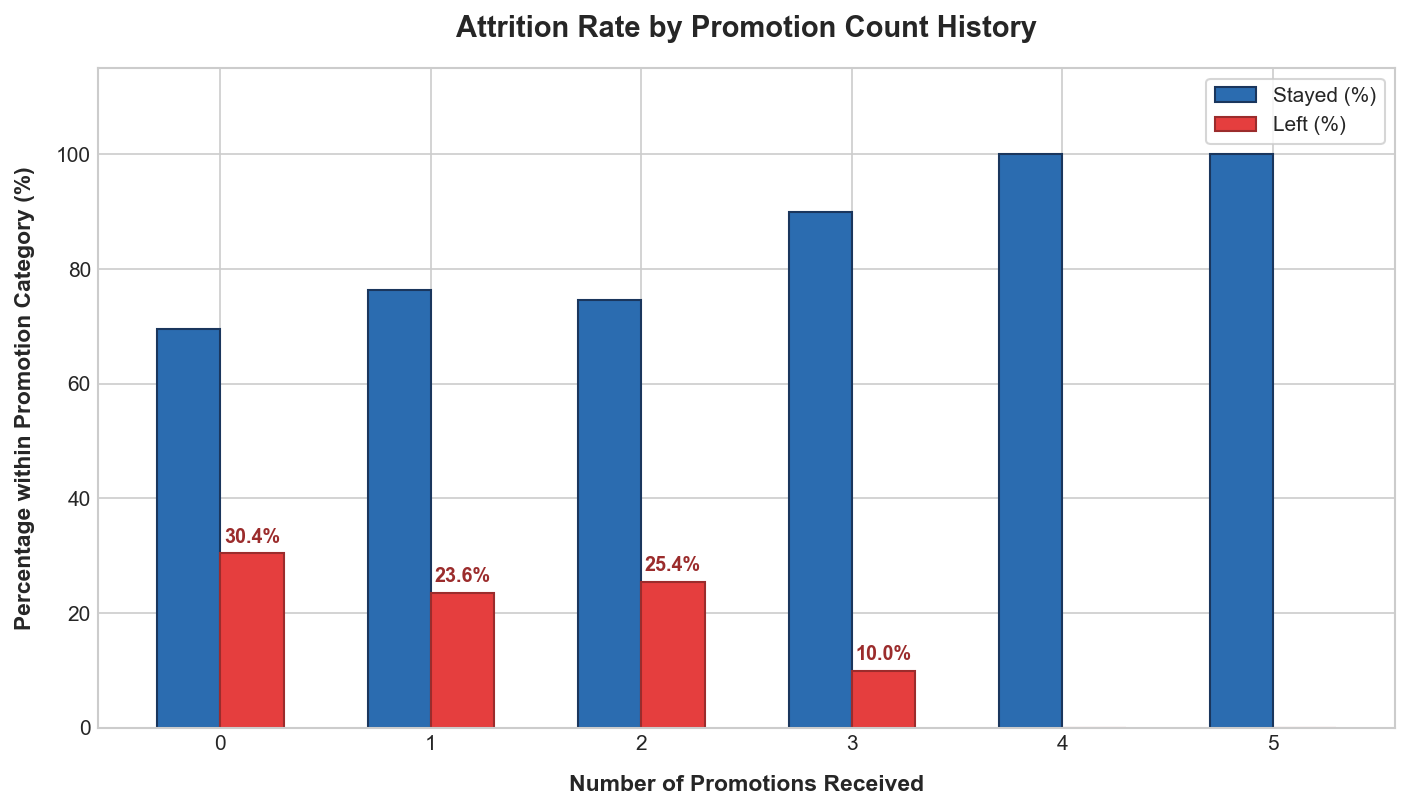

,Total_Employees,Stayed_Count,Left_Count,Attrition_Rate_%
promotion_count,,,,
0.0,240,167,73,30.42
1.0,178,136,42,23.60
2.0,67,50,17,25.37
3.0,10,9,1,10.00
4.0,4,4,0,0.00
5.0,1,1,0,0.00


In [26]:
promo_table = pd.crosstab(merged_df['promotion_count'], merged_df['exit_status'], normalize='index') * 100
promo_counts = pd.crosstab(merged_df['promotion_count'], merged_df['exit_status'])

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars_stayed = ax.bar(promo_table.index - 0.15, promo_table['No'], width=0.3, label='Stayed (%)', color='#2b6cb0', edgecolor='#1a365d')
bars_left = ax.bar(promo_table.index + 0.15, promo_table['Yes'], width=0.3, label='Left (%)', color='#e53e3e', edgecolor='#9b2c2c')

for bar in bars_left:
    yval = bar.get_height()
    if yval > 0:
        ax.text(bar.get_x() + bar.get_width()/2, yval + 1.2, f"{yval:.1f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#9b2c2c')

ax.set_title("Attrition Rate by Promotion Count History", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Number of Promotions Received", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Percentage within Promotion Category (%)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_xticks(promo_table.index)
ax.set_ylim(0, 115)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig('outputs/06_promotion_history_vs_exit.png', dpi=300)
plt.show()

promo_summary = pd.DataFrame({
    'Total_Employees': promo_counts.sum(axis=1),
    'Stayed_Count': promo_counts['No'],
    'Left_Count': promo_counts['Yes'],
    'Attrition_Rate_%': promo_table['Yes'].round(2)
})
display(promo_summary)

## 5. Key Findings & Business Insights
The two required key findings are computed dynamically from the processed data. We clearly distinguish empirical observations from possible business explanations:
- **Finding 1**: The department and job role with the highest attrition rates.
- **Finding 2**: The difference in average monthly overtime between employees who left and stayed.

In [27]:
# Programmatic calculation of findings
top_dept = dept_summary.index[0]
top_dept_rate = dept_summary.loc[top_dept, 'attrition_rate']
top_dept_left = int(dept_summary.loc[top_dept, 'left'])
top_dept_total = int(dept_summary.loc[top_dept, 'total'])

top_role = role_summary.index[-1]
top_role_rate = role_summary.loc[top_role, 'attrition_rate']
top_role_left = int(role_summary.loc[top_role, 'left'])
top_role_total = int(role_summary.loc[top_role, 'total'])

ot_left_mean = merged_df[merged_df['exit_status'] == 'Yes']['overtime_hours_monthly'].mean()
ot_stayed_mean = merged_df[merged_df['exit_status'] == 'No']['overtime_hours_monthly'].mean()
ot_diff = ot_left_mean - ot_stayed_mean
ot_pct_diff = (ot_diff / ot_stayed_mean) * 100

print("=" * 80)
print("AUTOMATED KEY FINDINGS (DATA-DRIVEN)")
print("=" * 80)

print("\n--- FINDING 1: HIGHEST ATTRITION CONCENTRATIONS ---")
print("1. EMPIRICAL OBSERVATION:")
print(f"   * Highest Department Attrition: {top_dept} at {top_dept_rate:.2f}% ({top_dept_left}/{top_dept_total} employees exited).")
print(f"     This is significantly higher than the company-wide average of {overall_attrition:.2f}%.")
print(f"   * Highest Job Role Attrition: '{top_role}' at {top_role_rate:.2f}% ({top_role_left}/{top_role_total} employees exited).")
print(f"     Followed by 'Recruiter' ({role_summary.loc['Recruiter', 'attrition_rate']:.2f}%) and 'Team Lead' ({role_summary.loc['Team Lead', 'attrition_rate']:.2f}%).")
print("2. POSSIBLE EXPLANATION:")
print("   * Elevated attrition in HR and frontline leadership (Team Leads) typically indicates intense recruitment pressure,")
print("     people-management stress, or higher external demand in the market for talent management roles.")

print("\n--- FINDING 2: OVERTIME WORKLOAD DISPARITY ---")
print("1. EMPIRICAL OBSERVATION:")
print(f"   * Employees who exited averaged {ot_left_mean:.2f} hours of monthly overtime.")
print(f"   * Employees who stayed averaged {ot_stayed_mean:.2f} hours of monthly overtime.")
print(f"   * Absolute difference: +{ot_diff:.2f} hours/month ({ot_pct_diff:.1f}% higher overtime workload for exited staff).")
print("2. POSSIBLE EXPLANATION:")
print("   * Chronic and elevated overtime hours correlate directly with workplace burnout and fatigue.")
print("     Unbalanced workloads without adequate rest or compensatory recovery create strong push factors driving employee departures.")
print("=" * 80)

AUTOMATED KEY FINDINGS (DATA-DRIVEN)

--- FINDING 1: HIGHEST ATTRITION CONCENTRATIONS ---
1. EMPIRICAL OBSERVATION:
   * Highest Department Attrition: HR at 36.36% (16/44 employees exited).
     This is significantly higher than the company-wide average of 26.60%.
   * Highest Job Role Attrition: 'HR Executive' at 46.15% (6/13 employees exited).
     Followed by 'Recruiter' (36.36%) and 'Team Lead' (36.11%).
2. POSSIBLE EXPLANATION:
   * Elevated attrition in HR and frontline leadership (Team Leads) typically indicates intense recruitment pressure,
     people-management stress, or higher external demand in the market for talent management roles.

--- FINDING 2: OVERTIME WORKLOAD DISPARITY ---
1. EMPIRICAL OBSERVATION:
   * Employees who exited averaged 21.52 hours of monthly overtime.
   * Employees who stayed averaged 15.61 hours of monthly overtime.
   * Absolute difference: +5.91 hours/month (37.9% higher overtime workload for exited staff).
2. POSSIBLE EXPLANATION:
   * Chronic an

## 6. Deliverables Generation & Validation
Export the cleaned dataset to `cleaned_employee_attrition.csv`, write the comprehensive summary report to `round1_eda_report.txt`, and verify all generated output artifacts.

In [28]:
# 1. Export Cleaned Dataset
cleaned_csv_path = 'cleaned_employee_attrition.csv'
merged_df.to_csv(cleaned_csv_path, index=False)
print(f"Exported merged clean dataset: '{cleaned_csv_path}' ({os.path.getsize(cleaned_csv_path):,} bytes)")

# 2. Export Summary Report
report_path = 'round1_eda_report.txt'
report_text = f"""========================================================================================
ROUND 1: DATA UNDERSTANDING, PREPARATION AND EXPLORATORY DATA ANALYSIS (EDA) REPORT
Project: CH05 – Employee Attrition Insight (DS Sprint Assessment)
Note: This dataset contains 500 synthetic employees and is intended for assessment practice.
========================================================================================

1. DATA UNDERSTANDING & INITIAL DATASET DETAILS
----------------------------------------------------------------------------------------
Five input CSV files were ingested and inspected:
- employees.csv   : {raw_data['employees'].shape[0]} records, {raw_data['employees'].shape[1]} attributes
  Attributes: {', '.join(raw_data['employees'].columns)}
  Missing Values: {raw_data['employees'].isnull().sum().sum()} | Duplicate Rows: {raw_data['employees'].duplicated().sum()}

- attendance.csv  : {raw_data['attendance'].shape[0]} records, {raw_data['attendance'].shape[1]} attributes
  Attributes: {', '.join(raw_data['attendance'].columns)}
  Missing Values: {raw_data['attendance'].isnull().sum().sum()} | Duplicate Rows: {attendance_dup_count} (Exact duplicates)

- compensation.csv: {raw_data['compensation'].shape[0]} records, {raw_data['compensation'].shape[1]} attributes
  Attributes: {', '.join(raw_data['compensation'].columns)}
  Missing Values: {raw_data['compensation'].isnull().sum().sum()} | Duplicate Rows: {raw_data['compensation'].duplicated().sum()}

- engagement.csv  : {raw_data['engagement'].shape[0]} records, {raw_data['engagement'].shape[1]} attributes
  Attributes: {', '.join(raw_data['engagement'].columns)}
  Missing Values: {missing_survey_count} in 'survey_score' | Duplicate Rows: {raw_data['engagement'].duplicated().sum()}

- movement.csv    : {raw_data['movement'].shape[0]} records, {raw_data['movement'].shape[1]} attributes
  Attributes: {', '.join(raw_data['movement'].columns)}
  Missing Values: {missing_promo_count} in 'promotion_count' | Duplicate Rows: {raw_data['movement'].duplicated().sum()}

Total Unique Employees Across All Files: 500


2. DATA PREPROCESSING & CLEANING SUMMARY
----------------------------------------------------------------------------------------
Step 1: Removed Duplicate Attendance Records
- Issue: attendance.csv contained {attendance_dup_count} redundant duplicate rows.
- Action: Deduplicated records by employee_id.
- Records Affected: {attendance_dup_count} rows dropped ({raw_data['attendance'].shape[0]} -> {attendance_clean.shape[0]} rows).

Step 2: Standardized Role Names
- Issue: Inconsistent capitalization (all uppercase) and extraneous leading/trailing whitespace in role entries.
- Action: Stripped whitespace, applied title case, and standardized technical role acronyms (IT Support, HR Manager, HR Executive, DevOps Engineer).
- Records Affected: {roles_affected} records corrected across 10 distinct job title variations. Reduced unique role representations from 29 noisy labels to 19 valid roles.

Step 3: Imputed Missing Engagement Survey Scores
- Issue: {missing_survey_count} missing entries (4.0% of cohort) in 'survey_score'.
- Action: Applied robust median imputation (median = {survey_score_median:.1f}).
- Records Affected: {missing_survey_count} rows imputed.

Step 4: Detected and Treated Extreme Overtime Outliers
- Issue: Extreme overtime readings up to 220.0 hours/month detected via IQR analysis.
  Statistics: Q1 = {q1:.1f} hrs, Q3 = {q3:.1f} hrs, IQR = {iqr:.1f} hrs.
  Upper fence (Q3 + 1.5 * IQR) = {upper_fence:.1f} hrs.
- Action: Capped values exceeding {upper_fence:.1f} hours at the upper fence threshold (Winsorization) to avoid data loss while dampening outlier distortion.
- Records Affected: {overtime_outliers_count} records capped.

Step 5: Imputed Missing Promotion Count History
- Issue: {missing_promo_count} missing entries (3.0% of cohort) in 'promotion_count'.
- Action: Applied robust median imputation (median = {promo_median:.1f}).
- Records Affected: {missing_promo_count} rows imputed.

Step 6: Data Consistency Validation & Multi-Table Merge
- Verification: Validated 1-to-1 key consistency of employee_id across all 5 tables (100% match, 500 unique IDs).
- Action: Merged all tables using 'employee_id' as the primary key.
- Merged Dataset Dimensions: 500 rows, 18 columns (exactly 1 row per unique employee).
- Final Data Quality: 0 missing values, 0 duplicate records.


3. KEY EDA FINDINGS (DATA-DRIVEN)
----------------------------------------------------------------------------------------
Finding 1: Department & Job Role with Highest Attrition Rate
- Empirical Observation:
  * Department: The Human Resources (HR) department exhibits the highest attrition rate at {top_dept_rate:.2f}% ({top_dept_left}/{top_dept_total} employees left), followed by Operations at {dept_summary.loc['Operations', 'attrition_rate']:.2f}%. Both exceed the overall company attrition rate of {overall_attrition:.2f}%.
  * Role: Among individual job roles, '{top_role}' records the single highest attrition rate at {top_role_rate:.2f}% ({top_role_left}/{top_role_total} employees left), followed by Recruiter ({role_summary.loc['Recruiter', 'attrition_rate']:.2f}%) and Team Lead ({role_summary.loc['Team Lead', 'attrition_rate']:.2f}%).
- Possible Explanation:
  Elevated turnover in HR personnel and frontline leaders (Team Leads) is often indicative of acute operational stress, recruitment strain, and burnout during organizational reorganization or high hiring pressures.

Finding 2: Monthly Overtime Disparity Between Exited and Retained Employees
- Empirical Observation:
  * Retained Employees (Stayed): Average monthly overtime is {ot_stayed_mean:.2f} hours (median: {merged_df[merged_df['exit_status'] == 'No']['overtime_hours_monthly'].median():.2f} hrs, std: {merged_df[merged_df['exit_status'] == 'No']['overtime_hours_monthly'].std():.2f} hrs).
  * Exited Employees (Left): Average monthly overtime is {ot_left_mean:.2f} hours (median: {merged_df[merged_df['exit_status'] == 'Yes']['overtime_hours_monthly'].median():.2f} hrs, std: {merged_df[merged_df['exit_status'] == 'Yes']['overtime_hours_monthly'].std():.2f} hrs).
  * Absolute Difference: Employees who left worked on average +{ot_diff:.2f} more overtime hours per month than employees who stayed ({ot_pct_diff:.1f}% higher workload).
- Possible Explanation:
  Chronic overtime hours are a direct precursor to workplace exhaustion and dissatisfaction. Sustained elevated overtime disproportionately accelerates employee departures when unmitigated by workload rebalancing.


4. ARTIFACTS AND OUTPUT FILES GENERATED
----------------------------------------------------------------------------------------
- Merged Clean Dataset : cleaned_employee_attrition.csv (500 rows, 18 columns)
- Summary Report        : round1_eda_report.txt
- Visualizations        :
  1. outputs/01_attrition_rate_by_department.png
  2. outputs/02_attrition_rate_by_job_role.png
  3. outputs/03_tenure_comparison.png
  4. outputs/04_overtime_comparison.png
  5. outputs/05_engagement_score_comparison.png
  6. outputs/06_promotion_history_vs_exit.png
========================================================================================
"""

with open(report_path, 'w', encoding='utf-8') as f:
    f.write(report_text)
print(f"Exported summary report: '{report_path}' ({os.path.getsize(report_path):,} bytes)")

# 3. Check outputs folder
print("\nVerifying Generated PNG Charts in 'outputs/':")
for chart_file in sorted(os.listdir('outputs')):
    if chart_file.endswith('.png'):
        full_p = os.path.join('outputs', chart_file)
        print(f"  [OK] {chart_file} ({os.path.getsize(full_p):,} bytes)")

print("\nRound 1 execution and export completed successfully.")

Exported merged clean dataset: 'cleaned_employee_attrition.csv' (45,771 bytes)
Exported summary report: 'round1_eda_report.txt' (5,829 bytes)

Verifying Generated PNG Charts in 'outputs/':
  [OK] 01_attrition_rate_by_department.png (155,117 bytes)
  [OK] 02_attrition_rate_by_job_role.png (387,441 bytes)
  [OK] 03_tenure_comparison.png (245,990 bytes)
  [OK] 04_overtime_comparison.png (145,713 bytes)
  [OK] 05_engagement_score_comparison.png (252,542 bytes)
  [OK] 06_promotion_history_vs_exit.png (133,859 bytes)
  [OK] confusion_matrix.png (89,349 bytes)
  [OK] feature_importance.png (261,648 bytes)

Round 1 execution and export completed successfully.
